CELL 1

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


# CELL 2 — Import library

In [ ]:
import os
import numpy as np
import nibabel as nib
import cv2
from tqdm import tqdm


# CELL 3 — KHAI BÁO ĐƯỜNG DẪN & OUTPUT

In [ ]:
# ===== DATA GỐC =====
ROOT_DIR = "/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao/Task07_Pancreas_Raw/Task07_Pancreas"
IMG_DIR  = os.path.join(ROOT_DIR, "imagesTr")
LBL_DIR  = os.path.join(ROOT_DIR, "labelsTr")

# ===== OUTPUT SAU TIỀN XỬ LÝ =====
OUT_ROOT = "/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix"

OUT_IMG = os.path.join(OUT_ROOT, "image")   # ảnh CT 2D ROI tumor
OUT_MSK = os.path.join(OUT_ROOT, "label")   # mask tumor 2D

os.makedirs(OUT_IMG, exist_ok=True)
os.makedirs(OUT_MSK, exist_ok=True)

# ===== INPUT SIZE CHO ATTENTION GATE U-NET =====
TARGET_SIZE = 256   # CHỐT 256×256


# I/ TIỀN XỬ LÝ ẢNH

# CELL 4 — HÀM WINDOWING HU (THEO MÔ TẢ BÀI BÁO 2023)

In [ ]:
def hu_window(img):
    """
    HU windowing theo mô tả:
    HU <= -128  -> 0
    HU >= 127   -> 255
    """
    img = np.clip(img, -128, 127)
    img = (img + 128) / 255.0   # normalize về [0,1]
    return img.astype(np.float32)


# CELL 5 — HÀM CROP ROI DỰA TRÊN PANCREAS (TIGHT, KHÔNG ĐEN)

In [ ]:
def crop_roi_by_pancreas(image, mask, margin=10):
    """
    Crop ROI dựa trên pancreas (label=1)
    """
    pancreas_mask = (mask == 1) | (mask == 2)  # pancreas + tumor

    coords = np.where(pancreas_mask)
    if len(coords[0]) == 0:
        return None, None

    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    y_min = max(0, y_min - margin)
    x_min = max(0, x_min - margin)
    y_max = min(image.shape[0], y_max + margin)
    x_max = min(image.shape[1], x_max + margin)

    img_crop = image[y_min:y_max, x_min:x_max]
    msk_crop = mask[y_min:y_max, x_min:x_max]

    return img_crop, msk_crop


# CELL 6 — RESIZE ROI (KHÔNG PADDING ĐEN)

In [ ]:
def resize_roi(img, mask, size=256):
    img_r = cv2.resize(img, (size, size), interpolation=cv2.INTER_LINEAR)
    msk_r = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    return img_r, msk_r


# CELL 7 — TIỀN XỬ LÝ CHÍNH (3D → 2D → TUMOR ROI)

In [ ]:
for fname in tqdm(sorted(os.listdir(IMG_DIR))):
    # Bỏ qua file ẩn macOS (._xxx) và file không phải .nii.gz
    if fname.startswith("._") or not fname.endswith(".nii.gz"):
        continue

    img_path = os.path.join(IMG_DIR, fname)
    lbl_path = os.path.join(LBL_DIR, fname)

    img_nii = nib.load(img_path).get_fdata()
    lbl_nii = nib.load(lbl_path).get_fdata()

    case_id = fname.replace(".nii.gz", "")

    for z in range(img_nii.shape[2]):
        img_slice = img_nii[:, :, z]
        lbl_slice = lbl_nii[:, :, z]

        # 👉 CHỈ GIỮ SLICE CÓ TUMOR
        if not np.any(lbl_slice == 2):
            continue

        # 1️⃣ HU windowing
        img_slice = hu_window(img_slice)

        # 2️⃣ Crop ROI theo pancreas
        img_crop, msk_crop = crop_roi_by_pancreas(img_slice, lbl_slice)

        if img_crop is None:
            continue

        # 3️⃣ Resize ROI
        img_final, msk_final = resize_roi(img_crop, msk_crop, TARGET_SIZE)

        # 👉 CHỈ GIỮ MASK TUMOR (BINARY)
        tumor_mask = (msk_final == 2).astype(np.uint8)

        # Save
        out_name = f"{case_id}_slice{z:03d}.npy"
        np.save(os.path.join(OUT_IMG, out_name), img_final)
        np.save(os.path.join(OUT_MSK, out_name), tumor_mask)

100%|██████████| 285/285 [14:59<00:00,  3.16s/it]


# CELL 8: XEM ẢNH SAU KHI TIỀN XỬ LÝ

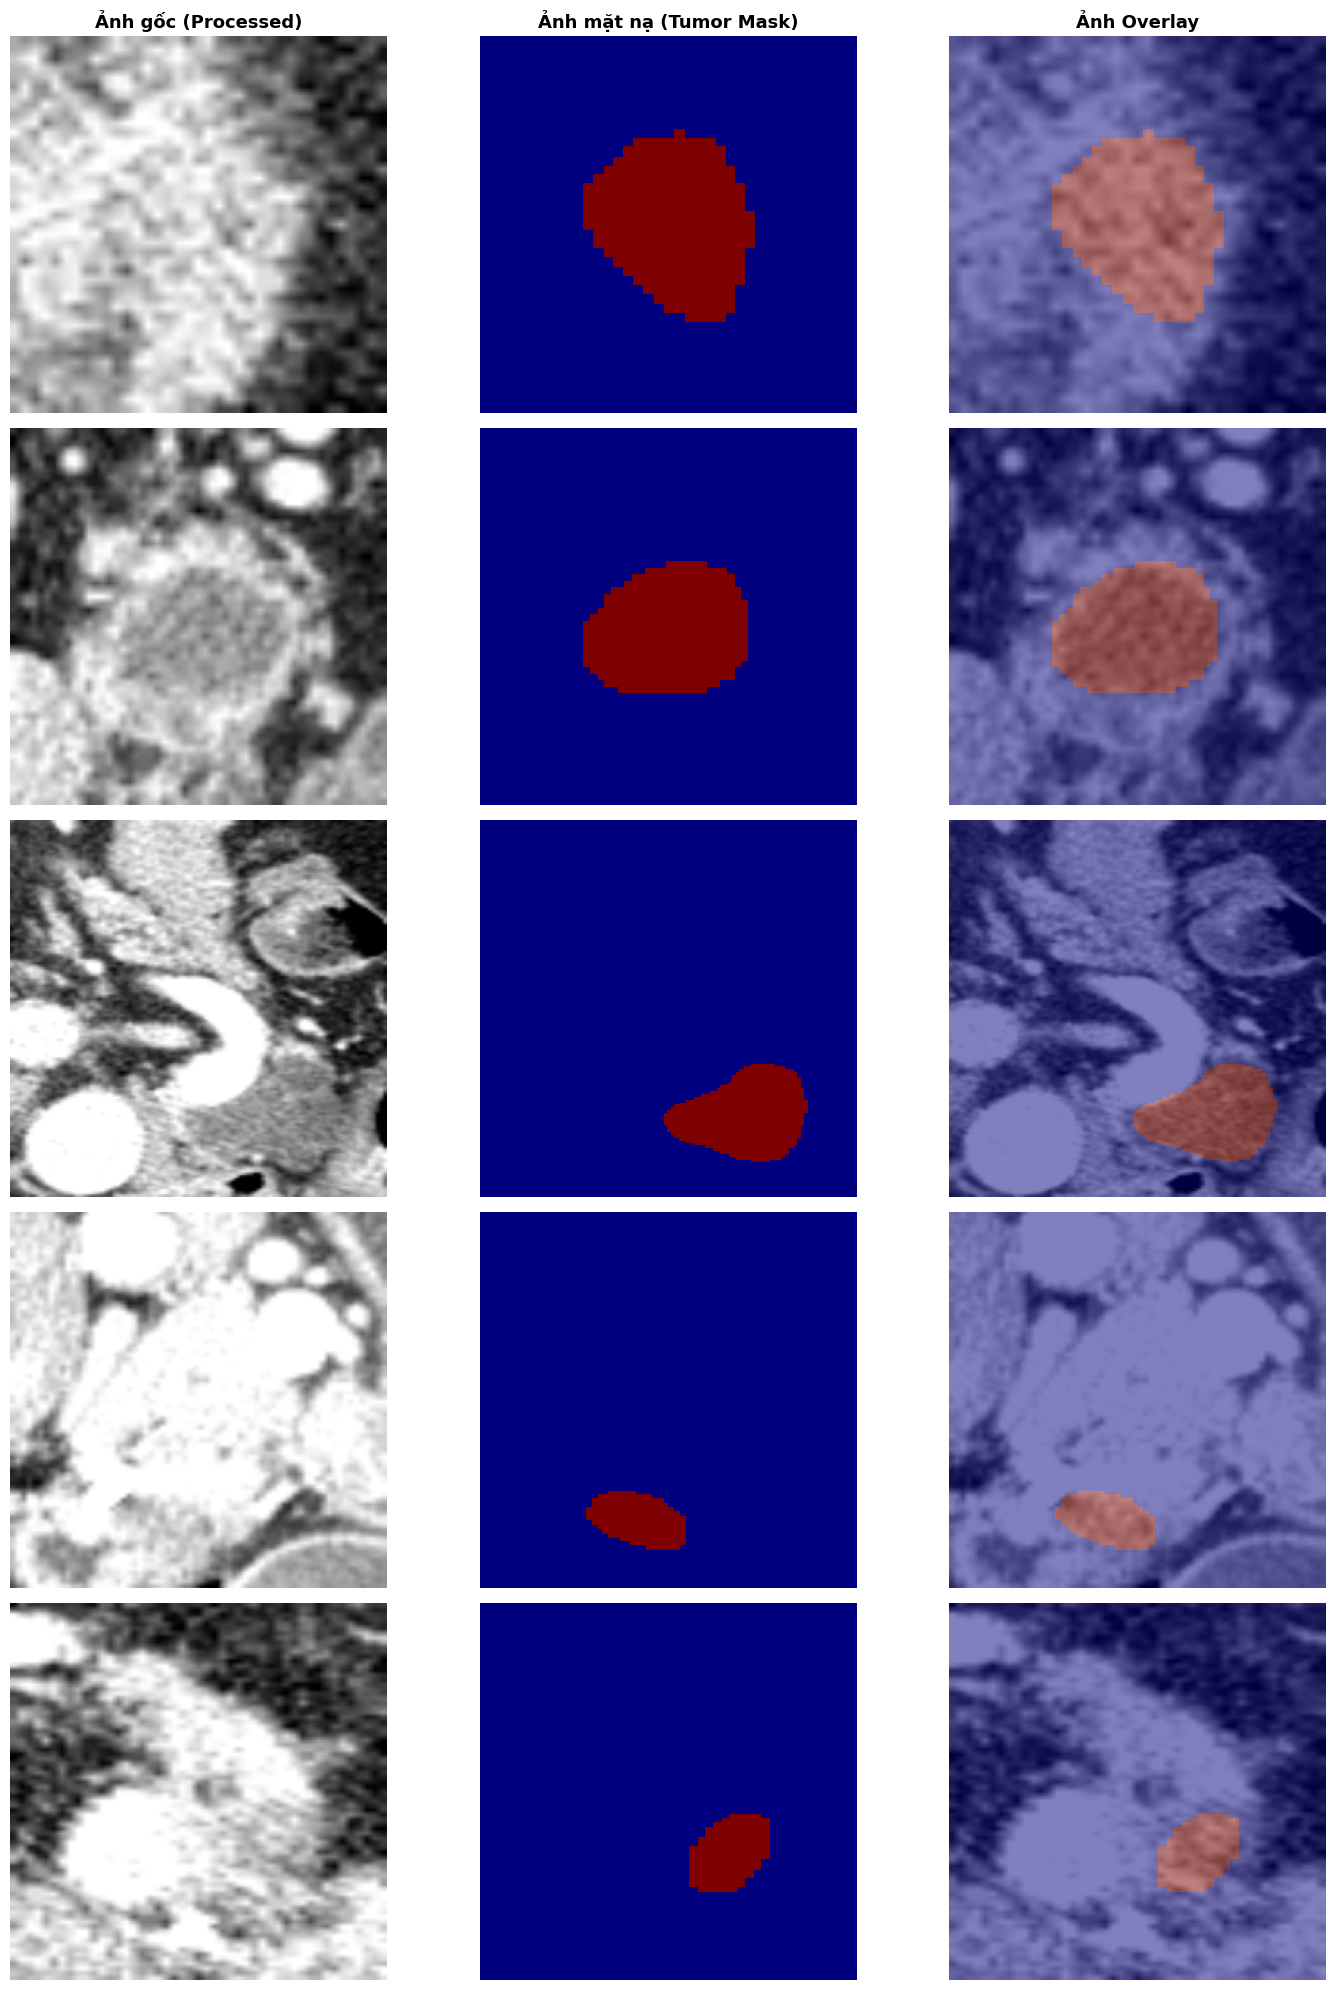

In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

DIR_PROCESSED = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix/'

def visualize_processed(num_samples=5):
    img_dir = os.path.join(DIR_PROCESSED, 'image')
    lbl_dir = os.path.join(DIR_PROCESSED, 'label')

    files = [f for f in os.listdir(img_dir) if f.endswith('.npy')]
    samples = random.sample(files, min(num_samples, len(files)))

    fig, axes = plt.subplots(len(samples), 3, figsize=(15, 4 * len(samples)))

    # Trường hợp chỉ có 1 sample
    if len(samples) == 1:
        axes = np.expand_dims(axes, axis=0)

    # Tiêu đề cột
    col_titles = ["Ảnh gốc (Processed)", "Ảnh mặt nạ (Tumor Mask)", "Ảnh Overlay"]
    for j, title in enumerate(col_titles):
        axes[0, j].set_title(title, fontsize=13, fontweight='bold')

    for i, fname in enumerate(samples):
        img = np.load(os.path.join(img_dir, fname))
        lbl = np.load(os.path.join(lbl_dir, fname))

        # 1️⃣ Ảnh gốc (processed image)
        axes[i, 0].imshow(img, cmap='gray')
        axes[i, 0].set_ylabel(fname, fontsize=9)
        axes[i, 0].set_xlabel(f"Shape: {img.shape}\nMin: {img.min():.2f}, Max: {img.max():.2f}")

        # 2️⃣ Ảnh mặt nạ (mask)
        axes[i, 1].imshow(lbl, cmap='jet', interpolation='nearest')
        axes[i, 1].set_xlabel(f"Classes: {np.unique(lbl)}")

        # 3️⃣ Ảnh overlay
        axes[i, 2].imshow(img, cmap='gray')
        axes[i, 2].imshow(lbl, cmap='jet', alpha=0.5, interpolation='nearest')
        axes[i, 2].set_xlabel("Overlay Image + Tumor Mask")

        for j in range(3):
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.show()

# --- CHẠY ---
visualize_processed(5)


# II/ CHIA TẬP DỮ LIỆU

# CELL 9: CHIA THEO MÃ SỐ BỆNH NHÂN

Với 281 bệnh nhân, tập dữ liệu của bạn KHÁ lớn, một tín hiệu rất tốt, độ tin cậy của mô hình sẽ cao hơn hẳn.

Theo chiến lược 70% Train - 20% Val - 10% Test, chúng ta sẽ chia 281 bệnh nhân như sau:

Train: ~197 bệnh nhân.

Validation: ~56 bệnh nhân.

Test: ~28 bệnh nhân.

-->chia theo bệnh nhân và lưu ra 3 file: train.csv, val.csv, test.csv

KIỂM TRA PHÂN PHỐI STT CỦA 5 BỆNH NHÂN ĐẦU TIÊN

In [13]:
import os
import numpy as np

# 1. Đường dẫn tới thư mục chứa ảnh
image_dir = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix/image'

# 2. Lấy danh sách tất cả các file trong thư mục
all_files = os.listdir(image_dir)

# 3. Trích xuất ID bệnh nhân
patient_ids = set() # Sử dụng set để tự động loại bỏ các ID trùng lặp

print("Đang quét và trích xuất ID bệnh nhân...")

for filename in all_files:
    if filename.endswith(".npy"):
        # Tên file mẫu: pancreas_001_slice52.npy
        # Tách chuỗi dựa trên dấu gạch dưới '_'
        parts = filename.split('_')

        # ID bệnh nhân sẽ là 2 phần đầu ghép lại: "pancreas" + "_" + "001"
        # parts[0] = pancreas, parts[1] = 001
        if len(parts) >= 2:
            patient_id = f"{parts[0]}_{parts[1]}"
            patient_ids.add(patient_id)

# 4. Chuyển về dạng list và sắp xếp để dễ nhìn
sorted_patient_ids = sorted(list(patient_ids))

# 5. In kết quả
print("-" * 30)
print(f"TỔNG SỐ BỆNH NHÂN TÌM THẤY: {len(sorted_patient_ids)}")
print("-" * 30)
print("Danh sách mã bệnh nhân:")
print(sorted_patient_ids)

# Kiểm tra thử một vài ID đầu tiên
if len(sorted_patient_ids) > 0:
    print("-" * 30)
    print(f"Ví dụ 5 bệnh nhân đầu tiên: {sorted_patient_ids[:5]}")

Đang quét và trích xuất ID bệnh nhân...
------------------------------
TỔNG SỐ BỆNH NHÂN TÌM THẤY: 281
------------------------------
Danh sách mã bệnh nhân:
['pancreas_001', 'pancreas_004', 'pancreas_005', 'pancreas_006', 'pancreas_010', 'pancreas_012', 'pancreas_015', 'pancreas_016', 'pancreas_018', 'pancreas_019', 'pancreas_021', 'pancreas_024', 'pancreas_025', 'pancreas_028', 'pancreas_029', 'pancreas_032', 'pancreas_035', 'pancreas_037', 'pancreas_040', 'pancreas_041', 'pancreas_042', 'pancreas_043', 'pancreas_045', 'pancreas_046', 'pancreas_048', 'pancreas_049', 'pancreas_050', 'pancreas_051', 'pancreas_052', 'pancreas_055', 'pancreas_056', 'pancreas_058', 'pancreas_061', 'pancreas_064', 'pancreas_066', 'pancreas_067', 'pancreas_069', 'pancreas_070', 'pancreas_071', 'pancreas_074', 'pancreas_075', 'pancreas_077', 'pancreas_078', 'pancreas_080', 'pancreas_081', 'pancreas_083', 'pancreas_084', 'pancreas_086', 'pancreas_087', 'pancreas_088', 'pancreas_089', 'pancreas_091', 'pancreas

CHIA TẬP DL 70-20-10

In [14]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN
# ==========================================
# Sử dụng thư mục đã tiền xử lý (ảnh sạch, crop 256x256, uint8)
base_dir = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix/'

image_dir = os.path.join(base_dir, 'image')
label_dir = os.path.join(base_dir, 'label')
output_dir = os.path.join(base_dir, 'csv_files') # Nơi lưu 3 file CSV

# Tạo thư mục lưu CSV nếu chưa có
os.makedirs(output_dir, exist_ok=True)

# ==========================================
# 2. LẤY DANH SÁCH BỆNH NHÂN (PATIENT IDs)
# ==========================================
print("--> Đang quét file để lấy ID bệnh nhân...")

# Lấy tất cả file .npy trong thư mục image
all_files = [f for f in os.listdir(image_dir) if f.endswith('.npy')]
patient_ids = set()

for filename in all_files:
    # Ví dụ filename: pancreas_001_slice52.npy
    # Cấu trúc: [tên]_[mã]_[sliceXXX].npy
    parts = filename.split('_')

    # Ghép lại thành ID bệnh nhân: pancreas_001
    if len(parts) >= 2:
        pid = f"{parts[0]}_{parts[1]}"
        patient_ids.add(pid)

# Sắp xếp để đảm bảo tính nhất quán mỗi lần chạy
patient_ids = sorted(list(patient_ids))
print(f"--> Tổng số bệnh nhân tìm thấy: {len(patient_ids)}")

# ==========================================
# 3. CHIA TẬP DỮ LIỆU (70% - 20% - 10%)
# ==========================================
# Bước 1: Tách 10% cho Test (Giữ lại 90% cho Train+Val)
train_val_ids, test_ids = train_test_split(patient_ids, test_size=0.10, random_state=42)

# Bước 2: Tách 20% tổng số cho Validation từ phần còn lại
# Tỷ lệ cần cắt trong tập còn lại = 0.2 / 0.9 = 0.2222...
val_size_adjusted = 0.2 / 0.9
train_ids, val_ids = train_test_split(train_val_ids, test_size=val_size_adjusted, random_state=42)

# Chuyển về set để tra cứu cho nhanh
train_ids_set = set(train_ids)
val_ids_set = set(val_ids)
test_ids_set = set(test_ids)

print(f"--> Phân chia theo Bệnh nhân:")
print(f"    - Train     : {len(train_ids)} bệnh nhân")
print(f"    - Validation: {len(val_ids)} bệnh nhân")
print(f"    - Test      : {len(test_ids)} bệnh nhân")

# ==========================================
# 4. GÁN FILE VÀO DATAFRAME
# ==========================================
data_list = [] # List chứa thông tin tất cả các file

print("--> Đang gán nhãn tập dữ liệu cho từng file ảnh...")
for filename in all_files:
    # Lấy lại ID từ tên file
    parts = filename.split('_')
    pid = f"{parts[0]}_{parts[1]}"

    # Đường dẫn đầy đủ
    img_path_full = os.path.join(image_dir, filename)
    label_path_full = os.path.join(label_dir, filename) # <-- Đã đổi tên biến cho rõ nghĩa

    # Xác định file này thuộc tập nào dựa trên ID bệnh nhân
    subset = None
    if pid in train_ids_set:
        subset = 'train'
    elif pid in val_ids_set:
        subset = 'validation'
    elif pid in test_ids_set:
        subset = 'test'

    # Kiểm tra an toàn: File label có tồn tại không?
    if subset and os.path.exists(label_path_full):
        data_list.append({
            'patient_id': pid,
            'image_path': img_path_full,
            'label_path': label_path_full,  # <--- QUAN TRỌNG: Tên cột chuẩn y khoa
            'subset': subset
        })

# Tạo DataFrame tổng
df_all = pd.DataFrame(data_list)

# ==========================================
# 5. LƯU RA 3 FILE CSV RIÊNG BIỆT
# ==========================================
# Lọc và lưu file Train
df_train = df_all[df_all['subset'] == 'train']
train_csv_path = os.path.join(output_dir, 'train.csv')
df_train.to_csv(train_csv_path, index=False)

# Lọc và lưu file Valid
df_val = df_all[df_all['subset'] == 'validation']
val_csv_path = os.path.join(output_dir, 'valid.csv')
df_val.to_csv(val_csv_path, index=False)

# Lọc và lưu file Test
df_test = df_all[df_all['subset'] == 'test']
test_csv_path = os.path.join(output_dir, 'test.csv')
df_test.to_csv(test_csv_path, index=False)

print("\n" + "="*40)
print("HOÀN TẤT! Đã lưu 3 file CSV tại thư mục csv_files:")
print(f"1. train.csv (Số lượng: {len(df_train)} ảnh)")
print(f"2. valid.csv (Số lượng: {len(df_val)} ảnh)")
print(f"3. test.csv  (Số lượng: {len(df_test)} ảnh)")
print("="*40)

# In thử 3 dòng đầu của tập train để kiểm tra
print("\nXem trước nội dung file train.csv:")
print(df_train.head(3))

--> Đang quét file để lấy ID bệnh nhân...
--> Tổng số bệnh nhân tìm thấy: 281
--> Phân chia theo Bệnh nhân:
    - Train     : 195 bệnh nhân
    - Validation: 57 bệnh nhân
    - Test      : 29 bệnh nhân
--> Đang gán nhãn tập dữ liệu cho từng file ảnh...

HOÀN TẤT! Đã lưu 3 file CSV tại thư mục csv_files:
1. train.csv (Số lượng: 1834 ảnh)
2. valid.csv (Số lượng: 480 ảnh)
3. test.csv  (Số lượng: 223 ảnh)

Xem trước nội dung file train.csv:
     patient_id                                         image_path  \
0  pancreas_278  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...   
1  pancreas_278  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...   
2  pancreas_278  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...   

                                          label_path subset  
0  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...  train  
1  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...  train  
2  /content/drive/MyDrive/Colab Notebooks/DATA_Pa...  train  


# CELL 10: XEM ẢNH TRONG CÁC TẬP TRAIN, VALID, TEST

--> Đang tải dữ liệu ngẫu nhiên từ train / valid / test ...


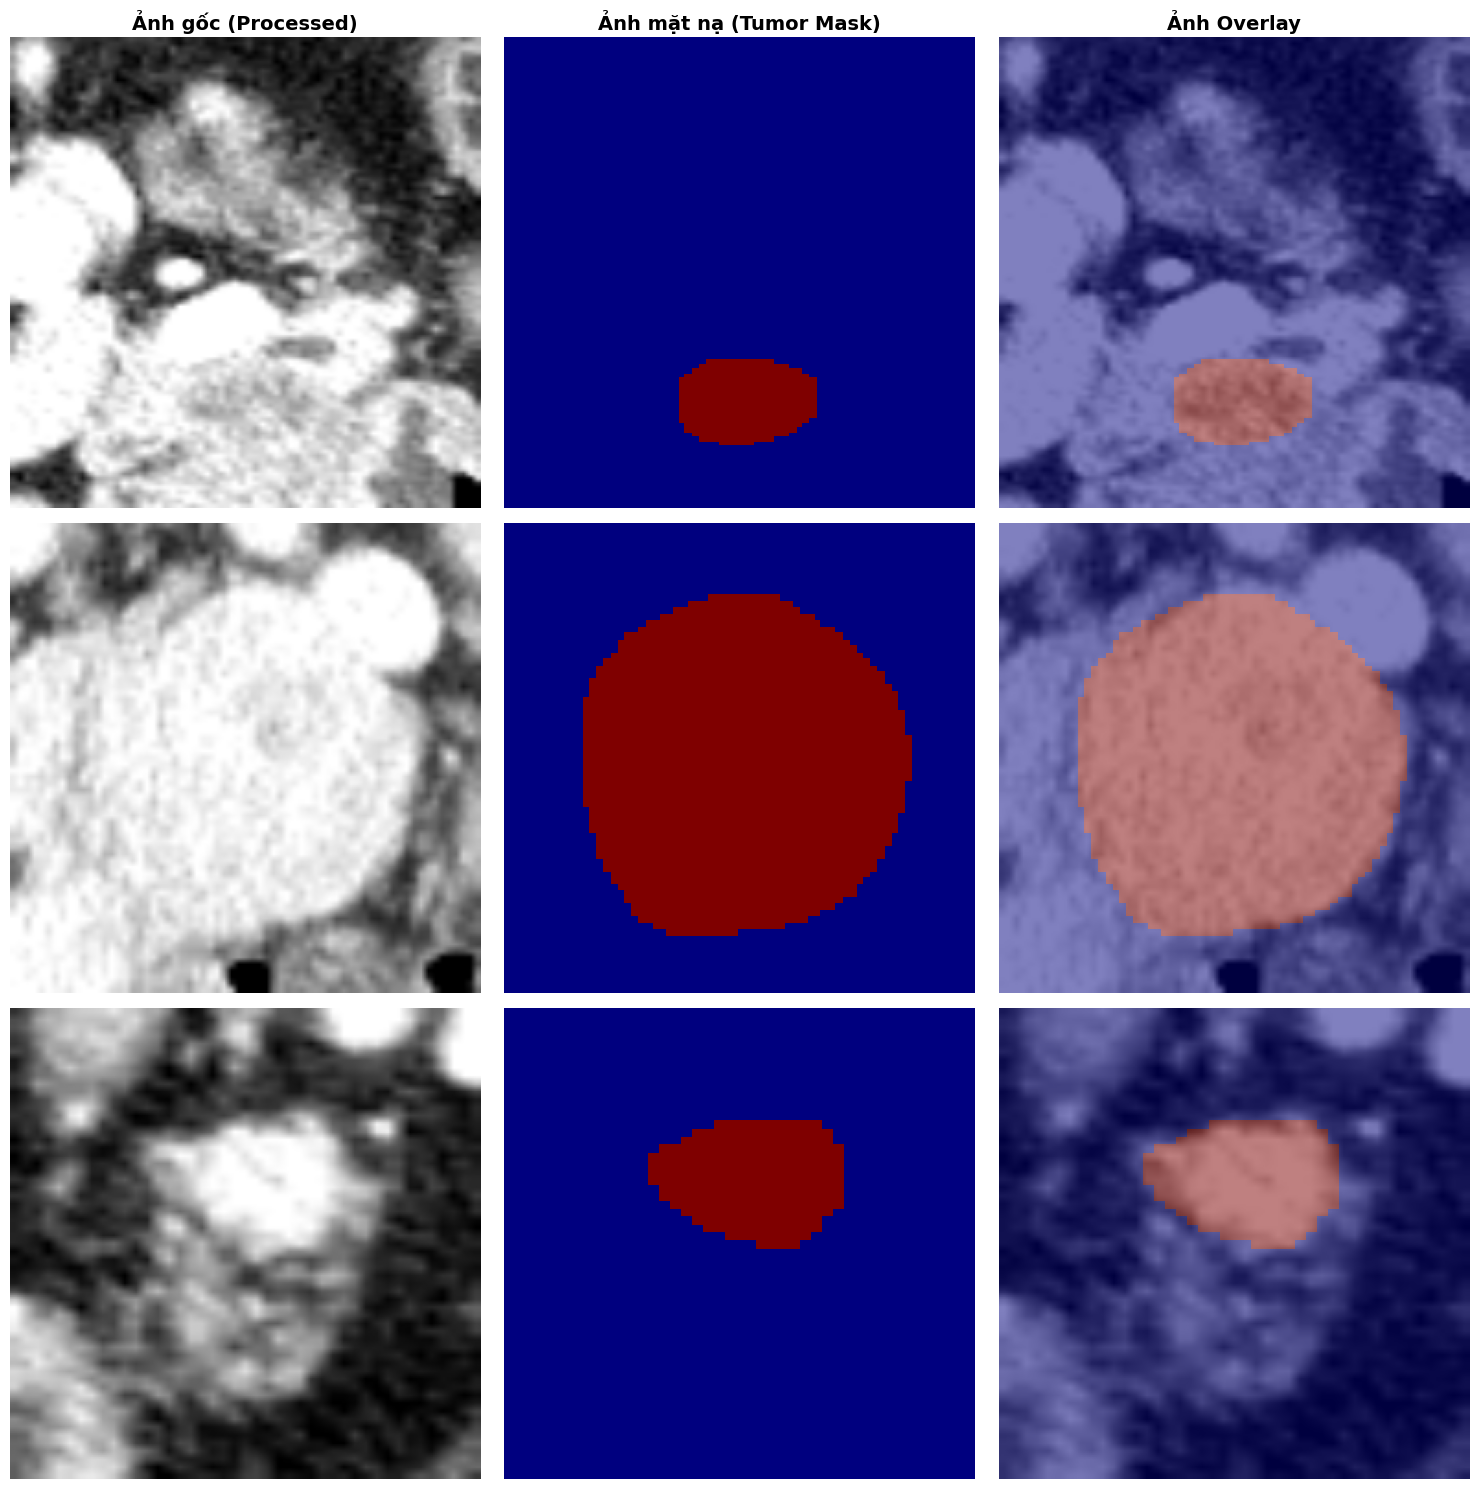

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# ==========================================
# CẤU HÌNH ĐƯỜNG DẪN
# ==========================================
csv_dir = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix//csv_files'
subsets = ['train', 'valid', 'test']

def visualize_subsets():
    # 3 dòng (train / valid / test), 3 cột (image / mask / overlay)
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))

    # Tiêu đề các cột
    col_titles = ['Ảnh gốc (Processed)', 'Ảnh mặt nạ (Tumor Mask)', 'Ảnh Overlay']
    for j, title in enumerate(col_titles):
        axes[0, j].set_title(title, fontsize=14, fontweight='bold')

    print("--> Đang tải dữ liệu ngẫu nhiên từ train / valid / test ...")

    for i, subset_name in enumerate(subsets):
        csv_path = os.path.join(csv_dir, f'{subset_name}.csv')

        if not os.path.exists(csv_path):
            print(f"LỖI: Không tìm thấy file {csv_path}")
            continue

        df = pd.read_csv(csv_path)

        if len(df) == 0:
            print(f"Cảnh báo: Tập {subset_name} rỗng!")
            continue

        # Lấy ngẫu nhiên 1 slice
        row = df.sample(1, random_state=None).iloc[0]

        img_path = row['image_path']
        lbl_path = row['label_path']
        patient_id = row['patient_id']

        try:
            image = np.load(img_path)
            label = np.load(lbl_path)
        except Exception as e:
            print(f"Lỗi đọc file ({subset_name}): {e}")
            continue

        # ===== CỘT 1: Ảnh gốc (processed image) =====
        axes[i, 0].imshow(image, cmap='gray')
        axes[i, 0].set_ylabel(
            f"Tập: {subset_name.upper()}\nPatient: {patient_id}",
            fontsize=12, fontweight='bold'
        )
        axes[i, 0].set_xlabel(
            f"Shape: {image.shape}\nMin: {image.min():.2f} | Max: {image.max():.2f}"
        )

        # ===== CỘT 2: Ảnh mặt nạ =====
        axes[i, 1].imshow(label, cmap='jet', interpolation='nearest')
        axes[i, 1].set_xlabel(f"Classes: {np.unique(label)}")

        # ===== CỘT 3: Ảnh overlay =====
        axes[i, 2].imshow(image, cmap='gray')
        axes[i, 2].imshow(label, cmap='jet', alpha=0.5, interpolation='nearest')
        axes[i, 2].set_xlabel("Overlay Image + Tumor Mask")

        # Tắt trục cho gọn
        for j in range(3):
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.show()

# --- CHẠY ---
visualize_subsets()


# BƯỚC KIỂM TRA SAU KHI TIỀN XỬ LÝ+CHIA TẬP DL

Dữ liệu đã được tiền xử lý, chuẩn hóa không gian, chia tách theo bệnh nhân, và kiểm định chất lượng nghiêm ngặt; đảm bảo phù hợp để huấn luyện mô hình Attention Gate U-Net trong bài toán phân đoạn khối u tuyến tụy????


================ DATASET SUMMARY =================

▶ TRAIN
  - Số slice     : 1834
  - Số bệnh nhân : 195
  - Phân bố pixel:
      Background (0): 89.23%
      Tumor      (1): 10.77%
---------------------------------------------
▶ VALID
  - Số slice     : 480
  - Số bệnh nhân : 57
  - Phân bố pixel:
      Background (0): 90.57%
      Tumor      (1): 9.43%
---------------------------------------------
▶ TEST
  - Số slice     : 223
  - Số bệnh nhân : 29
  - Phân bố pixel:
      Background (0): 92.15%
      Tumor      (1): 7.85%
---------------------------------------------

================ PATIENT LEAKAGE CHECK =================

✅ KHÔNG CÓ TRÙNG BỆNH NHÂN GIỮA CÁC TẬP

================ QUICK VISUAL CHECK =================



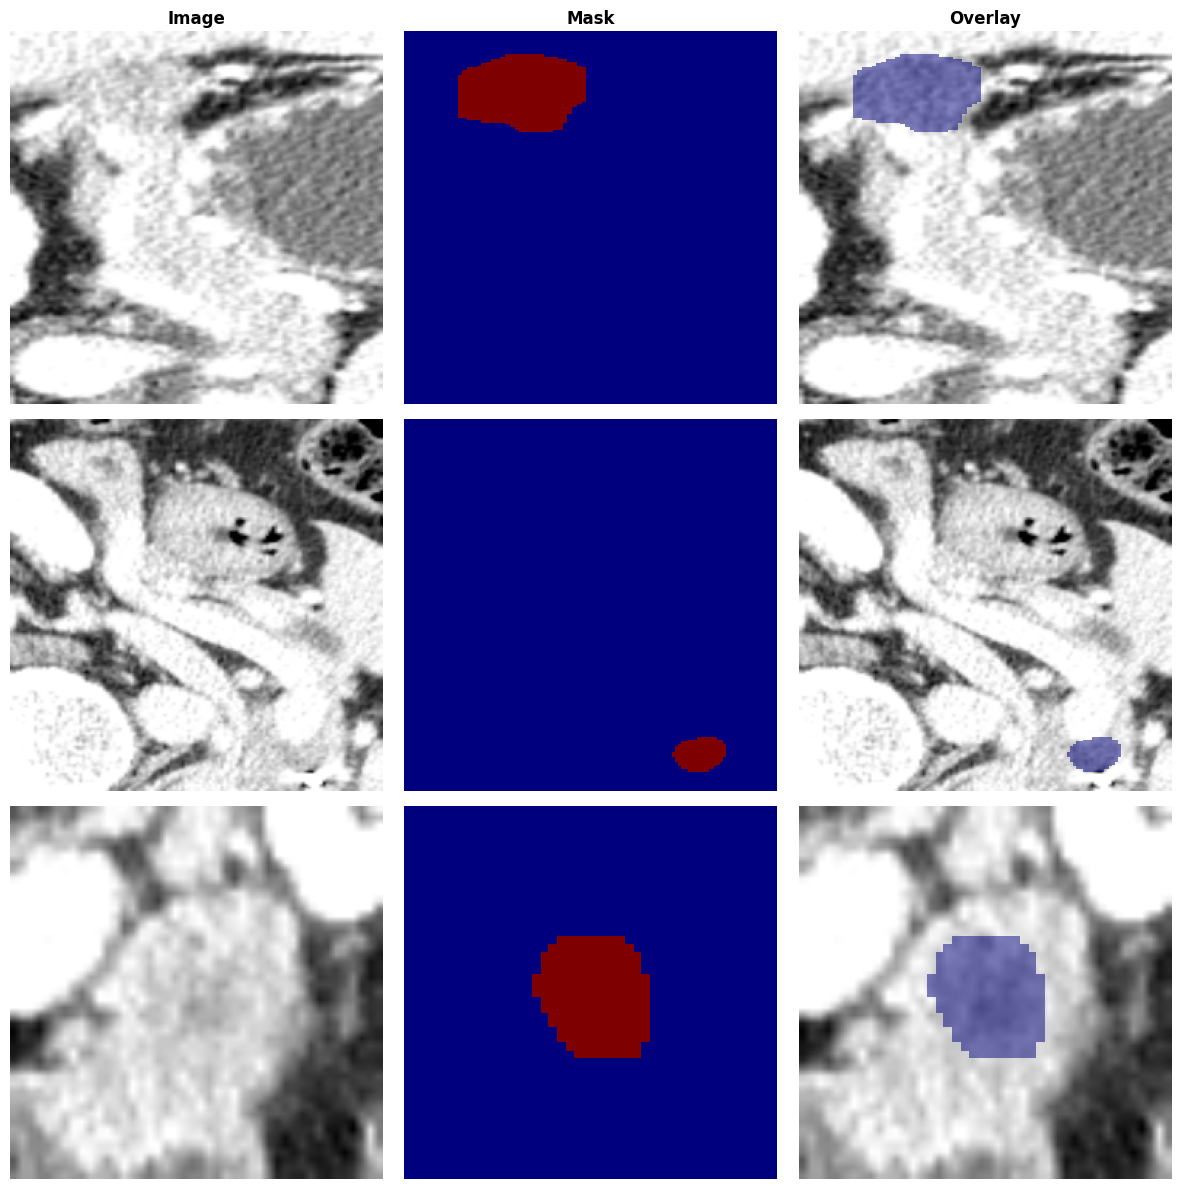


🎉 KẾT LUẬN CUỐI CÙNG:
✔ Dataset NHỊ PHÂN (0/1) hợp lệ
✔ Image–Mask khớp shape, dtype, range
✔ Không có NaN / Inf / class lạ
✔ Không trùng bệnh nhân giữa các tập
✔ Sẵn sàng huấn luyện Attention Gate U-Net


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# ================== CONFIG ==================
BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix/'
CSV_DIR  = os.path.join(BASE_DIR, 'csv_files')
SUBSETS  = ['train', 'valid', 'test']

# Dataset NHỊ PHÂN
VALID_CLASSES = {0, 1}
IMG_SHAPE = (256, 256)

# ================== HELPERS ==================
def check_image(img, name):
    # 1. Shape
    assert img.shape == IMG_SHAPE, f"{name}: Image shape sai {img.shape}"

    # 2. Dtype (chuẩn DL)
    assert img.dtype in [np.float32, np.float64], \
        f"{name}: Image dtype sai {img.dtype}"

    # 3. Value range sau normalize
    assert img.min() >= 0.0 and img.max() <= 1.0, \
        f"{name}: Image value out of [0,1], min={img.min()}, max={img.max()}"

    # 4. Không có NaN / Inf
    assert not np.isnan(img).any(), f"{name}: Image có NaN"
    assert not np.isinf(img).any(), f"{name}: Image có Inf"


def check_mask(mask, name):
    # 1. Shape
    assert mask.shape == IMG_SHAPE, f"{name}: Mask shape sai {mask.shape}"

    # 2. Dtype
    assert np.issubdtype(mask.dtype, np.integer), \
        f"{name}: Mask dtype không phải int ({mask.dtype})"

    # 3. Giá trị hợp lệ
    uniq = set(np.unique(mask))
    assert uniq.issubset(VALID_CLASSES), \
        f"{name}: Mask có class lạ {uniq}"

    # 4. Phải có tumor (vì dataset đã lọc)
    assert mask.sum() > 0, f"{name}: Mask KHÔNG có pixel tumor"


# ================== MAIN CHECK ==================
all_patient_sets = {}

print("\n================ DATASET SUMMARY =================\n")

for subset in SUBSETS:
    csv_path = os.path.join(CSV_DIR, f'{subset}.csv')
    assert os.path.exists(csv_path), f"❌ Không tìm thấy {csv_path}"

    df = pd.read_csv(csv_path)

    print(f"▶ {subset.upper()}")
    print(f"  - Số slice     : {len(df)}")
    print(f"  - Số bệnh nhân : {df['patient_id'].nunique()}")

    all_patient_sets[subset] = set(df['patient_id'].unique())

    class_counter = Counter()

    # Kiểm tra ngẫu nhiên 50 slice
    sample_df = df.sample(min(50, len(df)), random_state=42)

    for _, row in sample_df.iterrows():
        img_path = row['image_path']
        lbl_path = row['label_path']

        assert os.path.exists(img_path), f"❌ Missing image: {img_path}"
        assert os.path.exists(lbl_path), f"❌ Missing label: {lbl_path}"

        img = np.load(img_path)
        msk = np.load(lbl_path)

        check_image(img, img_path)
        check_mask(msk, lbl_path)

        class_counter.update(msk.flatten().tolist())

    # Thống kê pixel
    total_pixels = sum(class_counter.values())
    bg_ratio = class_counter[0] / total_pixels * 100
    tm_ratio = class_counter[1] / total_pixels * 100

    print("  - Phân bố pixel:")
    print(f"      Background (0): {bg_ratio:.2f}%")
    print(f"      Tumor      (1): {tm_ratio:.2f}%")
    print("-" * 45)

# ================== CHECK DATA LEAKAGE ==================
print("\n================ PATIENT LEAKAGE CHECK =================\n")

assert all_patient_sets['train'].isdisjoint(all_patient_sets['valid']), \
    "❌ Train ↔ Valid bị trùng bệnh nhân"
assert all_patient_sets['train'].isdisjoint(all_patient_sets['test']), \
    "❌ Train ↔ Test bị trùng bệnh nhân"
assert all_patient_sets['valid'].isdisjoint(all_patient_sets['test']), \
    "❌ Valid ↔ Test bị trùng bệnh nhân"

print("✅ KHÔNG CÓ TRÙNG BỆNH NHÂN GIỮA CÁC TẬP")

# ================== QUICK VISUAL CHECK ==================
print("\n================ QUICK VISUAL CHECK =================\n")

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
col_titles = ['Image', 'Mask', 'Overlay']
for ax, col in zip(axes[0], col_titles):
    ax.set_title(col, fontsize=12, fontweight='bold')

for i, subset in enumerate(SUBSETS):
    df = pd.read_csv(os.path.join(CSV_DIR, f'{subset}.csv'))
    row = df.sample(1, random_state=42).iloc[0]

    img = np.load(row['image_path'])
    msk = np.load(row['label_path'])

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 1].imshow(msk, cmap='jet', interpolation='nearest')
    axes[i, 2].imshow(img, cmap='gray')
    axes[i, 2].imshow(
        np.ma.masked_where(msk == 0, msk),
        cmap='jet', alpha=0.5, interpolation='nearest'
    )

    axes[i, 0].set_ylabel(subset.upper(), fontsize=12, fontweight='bold')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

print("\n🎉 KẾT LUẬN CUỐI CÙNG:")
print("✔ Dataset NHỊ PHÂN (0/1) hợp lệ")
print("✔ Image–Mask khớp shape, dtype, range")
print("✔ Không có NaN / Inf / class lạ")
print("✔ Không trùng bệnh nhân giữa các tập")
print("✔ Sẵn sàng huấn luyện Attention Gate U-Net")


# cell kiểm tra có tính pháp lý kỹ thuật

chứng minh 5 điều cùng lúc:

CSV KHÔNG chỉ chứa patient_id

CSV đã chứa đường dẫn đầy đủ tới từng slice .npy

Các file .npy THỰC SỰ TỒN TẠI trên disk

Image ↔ Label khớp tên slice

DataLoader 2D có thể load trực tiếp từng slice (không cần expand)

In [19]:
import os
import pandas as pd
import numpy as np

# ================== CONFIG ==================
BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/DATA_Pancreas_Segmentation_Bao_fix/'
CSV_DIR  = os.path.join(BASE_DIR, 'csv_files')
SUBSETS  = ['train', 'valid', 'test']

print("\n========== PROOF: CSV STRUCTURE & FILE EXISTENCE ==========\n")

for subset in SUBSETS:
    csv_path = os.path.join(CSV_DIR, f'{subset}.csv')
    print(f"▶ Checking {subset.upper()}")

    # 1. CSV tồn tại
    assert os.path.exists(csv_path), f"❌ Không tìm thấy {csv_path}"

    df = pd.read_csv(csv_path)

    # 2. CSV có đúng cột không?
    expected_cols = {'patient_id', 'image_path', 'label_path', 'subset'}
    assert expected_cols.issubset(set(df.columns)), \
        f"❌ {subset}.csv KHÔNG có đủ cột cần thiết"

    print(f"  ✔ Columns OK: {list(df.columns)}")
    print(f"  ✔ Total rows (slices): {len(df)}")

    # 3. Lấy ngẫu nhiên 5 dòng để kiểm tra thực tế
    sample_df = df.sample(min(5, len(df)), random_state=42)

    for i, row in sample_df.iterrows():
        img_path = row['image_path']
        lbl_path = row['label_path']
        pid      = row['patient_id']

        # 4. Đường dẫn là FILE .npy, KHÔNG phải ID
        assert img_path.endswith('.npy'), f"❌ image_path không phải file: {img_path}"
        assert lbl_path.endswith('.npy'), f"❌ label_path không phải file: {lbl_path}"

        # 5. File TỒN TẠI trên disk
        assert os.path.exists(img_path), f"❌ Không tồn tại image: {img_path}"
        assert os.path.exists(lbl_path), f"❌ Không tồn tại label: {lbl_path}"

        # 6. Kiểm tra đúng slice thuộc patient
        fname = os.path.basename(img_path)
        assert fname.startswith(pid + "_"), \
            f"❌ File {fname} KHÔNG thuộc patient {pid}"

        # 7. Load thử (chứng minh DataLoader 2D đọc được trực tiếp)
        img = np.load(img_path)
        lbl = np.load(lbl_path)

        assert img.ndim == 2, f"❌ Image không phải 2D: {img.shape}"
        assert lbl.ndim == 2, f"❌ Label không phải 2D: {lbl.shape}"

    print("  ✅ Sample slice check: PASSED\n")

print("==========================================================")
print("🎉 KẾT LUẬN CUỐI CÙNG:")
print("✔ CSV đã chứa TỪNG LÁT CẮT (slice) 2D cụ thể")
print("✔ KHÔNG phải chỉ chứa patient_id")
print("✔ DataLoader có thể đọc trực tiếp image_path / label_path")
print("❌ KHÔNG CẦN chạy code 'expand CSV / chữa cháy'")
print("==========================================================\n")



========== PROOF: CSV STRUCTURE & FILE EXISTENCE ==========

▶ Checking TRAIN
  ✔ Columns OK: ['patient_id', 'image_path', 'label_path', 'subset']
  ✔ Total rows (slices): 1834
  ✅ Sample slice check: PASSED

▶ Checking VALID
  ✔ Columns OK: ['patient_id', 'image_path', 'label_path', 'subset']
  ✔ Total rows (slices): 480
  ✅ Sample slice check: PASSED

▶ Checking TEST
  ✔ Columns OK: ['patient_id', 'image_path', 'label_path', 'subset']
  ✔ Total rows (slices): 223
  ✅ Sample slice check: PASSED

🎉 KẾT LUẬN CUỐI CÙNG:
✔ CSV đã chứa TỪNG LÁT CẮT (slice) 2D cụ thể
✔ KHÔNG phải chỉ chứa patient_id
✔ DataLoader có thể đọc trực tiếp image_path / label_path
❌ KHÔNG CẦN chạy code 'expand CSV / chữa cháy'



# III/ TĂNG CƯỜNG DỮ LIỆU

# III.1/ TĂNG CƯỜNG CỨNG (LƯU RA DRIVE)

--> ÍT DÙNG VÌ BẤT TIỆN (MỖI LẦN CẦN ĐIỀU CHỈNH CÁC KĨ THUẬT TĂNG CƯỜNG THÌLẠI MẤT NHIỀU THỜI GIAN ĐỂ LƯU RA DRIVE)

# loại dựa trên bài báo.

Rotation: Xoay +7 độ hoặc -11 độ.

Translation: Dịch chuyển 5 hoặc 10 pixel

# loại phù hợp hơn với ảnh CT

In [ ]:
def augment(img, lbl):
    if tf.random.uniform(()) > 0.5:
        img = tf.image.random_brightness(img, 0.05)

    if tf.random.uniform(()) > 0.5:
        img = tf.image.random_contrast(img, 0.9, 1.1)

    # ✅ BẮT BUỘC: giữ đúng range CT
    img = tf.clip_by_value(img, 0.0, 1.0)

    return img, lbl

# loại flip

In [ ]:
# ================= DATA AUGMENTATION (Flip ngang + dọc) =================
import os
import numpy as np
import shutil

BASE = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_fix4"

IMG_TRAIN = os.path.join(BASE, "image_train")
LBL_TRAIN = os.path.join(BASE, "label_train")

OUT_IMG = os.path.join(BASE, "image_train_augmentation")
OUT_LBL = os.path.join(BASE, "label_train_augmentation")

# ===== RESET THƯ MỤC =====
shutil.rmtree(OUT_IMG, ignore_errors=True)
shutil.rmtree(OUT_LBL, ignore_errors=True)

os.makedirs(OUT_IMG, exist_ok=True)
os.makedirs(OUT_LBL, exist_ok=True)

print("INPUT image_train :", len(os.listdir(IMG_TRAIN)))
print("INPUT label_train :", len(os.listdir(LBL_TRAIN)))


# ================= HÀM TĂNG CƯỜNG =================
def augment_and_save(fname, img_path, lbl_path):

    name = fname.replace(".npy", "")   # giữ tên gốc

    img = np.load(img_path)
    lbl = np.load(lbl_path)

    # ---- Lật ngang ----
    img_h = np.flip(img, axis=1)
    lbl_h = np.flip(lbl, axis=1)

    # ---- Lật dọc ----
    img_v = np.flip(img, axis=0)
    lbl_v = np.flip(lbl, axis=0)

    # ===== GỐC =====
    np.save(os.path.join(OUT_IMG, f"{name}_base.npy"), img)
    np.save(os.path.join(OUT_LBL, f"{name}_base.npy"), lbl)

    # ===== HFLIP =====
    np.save(os.path.join(OUT_IMG, f"{name}_hflip.npy"), img_h)
    np.save(os.path.join(OUT_LBL, f"{name}_hflip.npy"), lbl_h)

    # ===== VFLIP =====
    np.save(os.path.join(OUT_IMG, f"{name}_vflip.npy"), img_v)
    np.save(os.path.join(OUT_LBL, f"{name}_vflip.npy"), lbl_v)



# ================= DUYỆT THEO TÊN FILE =================
all_imgs = sorted([f for f in os.listdir(IMG_TRAIN) if f.endswith(".npy")])

missing = 0

for fname in all_imgs:

    img_path = os.path.join(IMG_TRAIN, fname)
    lbl_path = os.path.join(LBL_TRAIN, fname)

    if not os.path.exists(lbl_path):
        print("⚠ Thiếu mask cho:", fname)
        missing += 1
        continue

    augment_and_save(fname, img_path, lbl_path)


print("\n🎯 DONE!")
print("Thiếu mask:", missing)
print("OUTPUT image_train_augmentation :", len(os.listdir(OUT_IMG)))
print("OUTPUT label_train_augmentation :", len(os.listdir(OUT_LBL)))


kiểm chứng toàn bộ tính toàn vẹn của augmentation 👍

1️⃣ Kiểm tra số file trong 2 thư mục
2️⃣ Xác nhận các cặp ảnh–mask có khớp tên hay không
3️⃣ Kiểm tra mỗi slice có đủ:

_base / _hflip / _vflip


4️⃣ Phát hiện:

ảnh nhưng không có mask

mask nhưng không có ảnh

bệnh nhân bị thiếu augment

nhóm slice bị mất 1 trong 3 bản sao

In [ ]:
# =========================
# CELL 2 — Imports & Paths
# =========================
import os
import glob
from collections import defaultdict

BASE = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_fix4"

# =========================
# GHÉP CẶP AN TOÀN THEO TÊN
# =========================
def pair_image_mask(img_dir, msk_dir):
    """
    Ghép ảnh & mask theo cùng tên file
    — An toàn tuyệt đối, không lệ thuộc sort() —
    """

    imgs = sorted(glob.glob(os.path.join(img_dir, "*.npy")))
    msks = sorted(glob.glob(os.path.join(msk_dir, "*.npy")))

    img_dict = {os.path.basename(f): f for f in imgs}
    msk_dict = {os.path.basename(f): f for f in msks}

    pair_img, pair_msk = [], []
    missing = 0

    for name in sorted(img_dict.keys()):
        if name not in msk_dict:
            print(f"⚠ Thiếu mask cho: {name}")
            missing += 1
            continue

        pair_img.append(img_dict[name])
        pair_msk.append(msk_dict[name])

    print("✔ Số cặp khớp:", len(pair_img))
    print("⚠ Thiếu mask:", missing)
    print("-" * 40)

    return pair_img, pair_msk


# =========================
# LOAD TRAIN (AUGMENTATION)
# =========================
print("📌 LOAD TRAIN (AUGMENT)...")

TRAIN_IMG, TRAIN_MSK = pair_image_mask(
    os.path.join(BASE, "image_train_augmentation"),
    os.path.join(BASE, "label_train_augmentation")
)


# =========================
# LOAD VALID
# =========================
print("📌 LOAD VALID...")

VAL_IMG, VAL_MSK = pair_image_mask(
    os.path.join(BASE, "image_valid"),
    os.path.join(BASE, "label_valid")
)


# =========================
# LOAD TEST
# =========================
print("📌 LOAD TEST...")

TEST_IMG, TEST_MSK = pair_image_mask(
    os.path.join(BASE, "image_test"),
    os.path.join(BASE, "label_test")
)


# =========================
# SUMMARY
# =========================
print("\n🎯 SUMMARY DATASET")
print("Train:", len(TRAIN_IMG))
print("Val  :", len(VAL_IMG))
print("Test :", len(TEST_IMG))


KIỂM TRA:

👉 kiểm tra số slice trên từng bệnh nhân

👉 thống kê sau augment (base / hflip / vflip)

👉 xác nhận không rò rỉ bệnh nhân train → val → test

In [ ]:
import re
from collections import defaultdict, Counter
import os

# ==============================
# HÀM TÁCH MÃ BỆNH NHÂN
# pancreas_004_slice037_base.npy
#  → pancreas_004
# ==============================
def get_patient_id(fname):
    return fname.split("_slice")[0]


# ==============================
# HÀM NHẬN LOẠI AUGMENT
# ==============================
def get_aug_type(fname):

    if fname.endswith("_base.npy"):
        return "base"
    elif fname.endswith("_hflip.npy"):
        return "hflip"
    elif fname.endswith("_vflip.npy"):
        return "vflip"
    else:
        return "unknown"


# ==============================
# HÀM THỐNG KÊ TRONG 1 TẬP
# ==============================
def analyze_split(file_list, split_name):

    patient_slices = defaultdict(list)
    patient_aug = defaultdict(list)

    for path in file_list:
        fname = os.path.basename(path)

        pid = get_patient_id(fname)
        aug = get_aug_type(fname)

        patient_slices[pid].append(fname)
        patient_aug[pid].append(aug)

    print(f"\n====== 📊 {split_name.upper()} — PATIENT SLICE STATS ======")
    print("Số bệnh nhân:", len(patient_slices))

    total_slices = 0

    for pid, files in patient_slices.items():
        total_slices += len(files)

        aug_count = Counter(patient_aug[pid])

        print(f"\n🧩 {pid}")
        print("  Tổng slice:", len(files))
        print("  base :", aug_count['base'])
        print("  hflip:", aug_count['hflip'])
        print("  vflip:", aug_count['vflip'])

    print(f"\n➡ Tổng slice toàn tập {split_name}: {total_slices}")

    return set(patient_slices.keys())


In [ ]:
train_patients = analyze_split(TRAIN_IMG, "train")
val_patients   = analyze_split(VAL_IMG,   "val")
test_patients  = analyze_split(TEST_IMG,  "test")


KIỂM TRA DL CÓ BỊ RÒ RỈ KHÔNG?

In [ ]:
print("\n================= 🔍 CHECK DATA LEAKAGE =================")

inter_tr_va = train_patients.intersection(val_patients)
inter_tr_te = train_patients.intersection(test_patients)
inter_va_te = val_patients.intersection(test_patients)

if not inter_tr_va and not inter_tr_te and not inter_va_te:
    print("🎯 OK — Không có rò rỉ bệnh nhân giữa các tập 👍")
else:
    print("⚠ CẢNH BÁO — Có bệnh nhân xuất hiện ở nhiều tập!!!")

    if inter_tr_va:
        print("↪ Train ↔ Val:", inter_tr_va)

    if inter_tr_te:
        print("↪ Train ↔ Test:", inter_tr_te)

    if inter_va_te:
        print("↪ Val ↔ Test:", inter_va_te)


# III.2/ TĂNG CƯỜNG MỀM (ON-THE-FLY TRONG QUÁ TRÌNH TRAIN)

--> CÓ THỂ ĐIỀU CHỈNH CÁC KĨ THUẬT TĂNG CƯỜNG MÀ KHÔNG MẤT NHIỀU THỜI GIAN